# Module 14 — Fine-tuning de LLM : SFT, LoRA/QLoRA, DPO

> **Objectif** : savoir **quand** et **comment** adapter un grand modèle de langage (LLM) génératif à ses données : formater des conversations avec un *chat template*, ne calculer la perte que sur les réponses, estimer la mémoire nécessaire, choisir entre affinage complet, LoRA et QLoRA, puis aligner le modèle sur des préférences avec **DPO**, dont on dérive les maths et qu'on entraîne sur un exemple jouet en NumPy. Le code TRL / PEFT est donné prêt à exécuter sur GPU.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 6, 7 (CLM, SFT, DPO en aperçu), 8 (LoRA) |
| **Librairies** | `numpy`, `matplotlib`, `jinja2` ; `torch`, `transformers`, `trl`, `peft`, `bitsandbytes` (sections 6–8) |

> 🗓️ **Versions** : le code des sections 6 à 8 suit les API de TRL et PEFT telles que documentées en octobre 2026. Ces bibliothèques évoluent vite : en cas d'erreur, consulte la documentation de ta version (`pip show trl`).

**Plan**

1. Prompting, RAG ou fine-tuning ?
2. Les données : conversations et *chat templates*
3. La perte : seulement sur les réponses de l'assistant
4. *Packing* : ne pas gaspiller le calcul en padding
5. Le budget mémoire : affinage complet, LoRA, QLoRA
6. SFT avec TRL et LoRA / QLoRA
7. Aligner sur des préférences : la dérivation de DPO, et une démonstration NumPy
8. DPO avec TRL ; au-delà (RL à récompenses vérifiables)
9. Évaluer un LLM affiné
10. Récapitulatif et exercices

In [1]:
import json
import re

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

## 1. Prompting, RAG ou fine-tuning ?

Le fine-tuning est rarement la **première** chose à essayer. Chaque approche résout un problème différent :

| Besoin | Meilleure première approche | Pourquoi |
|---|---|---|
| Le modèle doit connaître des **faits** à jour, privés ou nombreux | **RAG** (module 16), KG-RAG (module 17) | les faits changent ; le RAG cite ses sources ; le fine-tuning mémorise mal et invente |
| Le modèle doit suivre un **format** précis, un **style**, un vocabulaire métier | prompting + exemples, puis **SFT** si insuffisant | le SFT excelle à imposer une forme |
| Le modèle doit apprendre une **compétence** nouvelle (une tâche structurée, une syntaxe, un raisonnement de domaine) | **SFT** sur de bons exemples | c'est un apprentissage de comportement |
| Le modèle doit **préférer** certaines réponses (ton, sécurité, concision) | **DPO** après SFT | apprend à partir de comparaisons |
| Coût / latence : remplacer un gros modèle par un petit | **distillation** (module 12) : SFT d'un petit modèle sur les sorties du gros | |
| Le modèle doit agir (appeler des outils) | prompting + tool calling (module 15) ; SFT si les appels sont mal formés | |

> 🎯 **Règle pratique** : on fine-tune pour changer le **comportement** (forme, compétence, préférences), on fait du RAG pour donner des **connaissances**. Les deux se combinent souvent : un modèle affiné pour bien utiliser un contexte récupéré.

## 2. Les données : conversations et *chat templates*

### 💡 Le format conversationnel

Un modèle « instruct » a été entraîné sur des conversations avec des rôles :
```json
{"messages": [
  {"role": "system", "content": "Tu es un assistant d'annotation de séquences."},
  {"role": "user", "content": "Quelles régions contient ce domaine ?"},
  {"role": "assistant", "content": "FR1 (1-26), CDR1 (27-38), ..."}
]}
```

Le modèle, lui, ne voit qu'**une seule chaîne de tokens**. Le **chat template** (un gabarit Jinja stocké avec le tokenizer) transforme la liste de messages en cette chaîne, avec des **tokens spéciaux** qui délimitent les rôles. Chaque famille de modèles a le sien : utiliser le mauvais template à l'entraînement ou à l'inférence dégrade fortement le modèle. C'est l'erreur la plus fréquente en fine-tuning.

In [2]:
from jinja2 import Template

# A ChatML-style template (the format used by several open model families), simplified
CHATML = Template(
    "{% for m in messages %}<|im_start|>{{ m.role }}\n{{ m.content }}<|im_end|>\n{% endfor %}"
    "{% if add_generation_prompt %}<|im_start|>assistant\n{% endif %}"
)

conversation = [
    {"role": "system", "content": "Tu es un assistant concis."},
    {"role": "user", "content": "Combien de CDR dans un domaine V ?"},
    {"role": "assistant", "content": "Trois : CDR1, CDR2 et CDR3."},
    {"role": "user", "content": "Et de régions charpente ?"},
    {"role": "assistant", "content": "Quatre : FR1 à FR4."},
]
print(CHATML.render(messages=conversation, add_generation_prompt=False))
print("--- at inference time, the prompt ends with an open assistant turn: ---")
print(CHATML.render(messages=conversation[:4], add_generation_prompt=True))

<|im_start|>system
Tu es un assistant concis.<|im_end|>
<|im_start|>user
Combien de CDR dans un domaine V ?<|im_end|>
<|im_start|>assistant
Trois : CDR1, CDR2 et CDR3.<|im_end|>
<|im_start|>user
Et de régions charpente ?<|im_end|>
<|im_start|>assistant
Quatre : FR1 à FR4.<|im_end|>

--- at inference time, the prompt ends with an open assistant turn: ---
<|im_start|>system
Tu es un assistant concis.<|im_end|>
<|im_start|>user
Combien de CDR dans un domaine V ?<|im_end|>
<|im_start|>assistant
Trois : CDR1, CDR2 et CDR3.<|im_end|>
<|im_start|>user
Et de régions charpente ?<|im_end|>
<|im_start|>assistant



Avec `transformers`, on n'écrit jamais ce gabarit à la main : `tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)` applique celui du modèle.

### Les jeux de données à construire

| Type | Format TRL | Usage |
|---|---|---|
| conversationnel | `{"messages": [...]}` | SFT d'un assistant |
| prompt / complétion | `{"prompt": [...], "completion": [...]}` | SFT d'une tâche (entrée → sortie) |
| préférences | `{"prompt": ..., "chosen": ..., "rejected": ...}` | DPO (section 7) |

**Qualité > quantité** : quelques milliers d'exemples **propres, divers et cohérents** valent mieux que des centaines de milliers d'exemples bruités (LIMA, Zhou et al., 2023, montrait qu'un millier d'exemples soignés suffisait à apprendre le *format* d'un assistant). Déduplique, retire les exemples contradictoires, et garde un jeu de test **jamais vu**.

## 3. La perte : seulement sur les réponses de l'assistant

### 📐 Le SFT est un modèle de langage causal (module 7)…

$$
\mathcal L_{\text{SFT}} = -\frac{1}{|\mathcal A|}\sum_{t\in\mathcal A}\log p_\theta(x_t\mid x_{<t})
$$

… mais la somme ne porte que sur l'ensemble $\mathcal A$ des positions des **réponses de l'assistant**. Les tokens du système et de l'utilisateur sont donnés en contexte, mais reçoivent l'étiquette `-100` (ignorés, modules 4 et 7). Sinon, le modèle apprend aussi à **écrire les questions** de l'utilisateur, ce qui gaspille sa capacité et peut le pousser à « continuer » la conversation à la place de l'utilisateur.

Construisons ce masque à la main, avec un tokenizer jouet (un token par mot ou balise), pour voir exactement ce que fait `assistant_only_loss=True` dans TRL :

In [3]:
def toy_tokenize(text):
    return re.findall(r"<\|im_start\|>|<\|im_end\|>|\n|[^\s<]+", text)


def build_example(messages):
    """Return tokens and labels (-100 everywhere except assistant answers and their end token)."""
    tokens, train_mask = [], []
    for m in messages:
        header = toy_tokenize(f"<|im_start|>{m['role']}\n")
        body = toy_tokenize(f"{m['content']}<|im_end|>\n")
        tokens += header + body
        is_answer = m["role"] == "assistant"
        train_mask += [False] * len(header) + [is_answer] * len(body)   # the model must also learn to STOP (<|im_end|>)
    return tokens, np.array(train_mask)

toks, mask = build_example(conversation)
for t, m in zip(toks, mask):
    if t != "\n":
        print(f"{t!r:20s} {'LOSS' if m else '-100'}")
print(f"\n{mask.sum()} / {len(mask)} tokens contribute to the loss ({mask.mean():.0%})")

'<|im_start|>'       -100
'system'             -100
'Tu'                 -100
'es'                 -100
'un'                 -100
'assistant'          -100
'concis.'            -100
'<|im_end|>'         -100
'<|im_start|>'       -100
'user'               -100
'Combien'            -100
'de'                 -100
'CDR'                -100
'dans'               -100
'un'                 -100
'domaine'            -100
'V'                  -100
'?'                  -100
'<|im_end|>'         -100
'<|im_start|>'       -100
'assistant'          -100
'Trois'              LOSS
':'                  LOSS
'CDR1,'              LOSS
'CDR2'               LOSS
'et'                 LOSS
'CDR3.'              LOSS
'<|im_end|>'         LOSS
'<|im_start|>'       -100
'user'               -100
'Et'                 -100
'de'                 -100
'régions'            -100
'charpente'          -100
'?'                  -100
'<|im_end|>'         -100
'<|im_start|>'       -100
'assistant'          -100
'Quatre'    

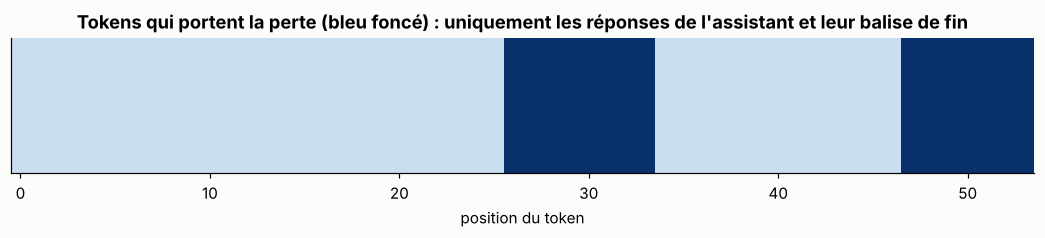

In [4]:
fig, ax = plt.subplots(figsize=(12, 1.6))
ax.imshow(mask[None, :], cmap="Blues", aspect="auto", vmin=-0.3, vmax=1)
ax.set_yticks([]); ax.set_xlabel("position du token"); ax.grid(False)
ax.set_title("Tokens qui portent la perte (bleu foncé) : uniquement les réponses de l'assistant et leur balise de fin")
plt.show()

> ⚠️ Le token de **fin de tour** (`<|im_end|>` ou équivalent) doit porter la perte : c'est ce qui apprend au modèle à **s'arrêter**. Un modèle affiné qui ne s'arrête jamais de générer a presque toujours ce bug (fin de séquence masquée, ou absente des données).

## 4. *Packing* : ne pas gaspiller le calcul en padding

Les conversations ont des longueurs très variables. En batch avec padding (module 1), une grande partie du calcul porte sur des PAD. Le **packing** concatène plusieurs exemples dans une même séquence de longueur fixe.

real tokens: 673,875
padding  : 1,544,696 processed tokens -> efficiency 44%
packing  : 675,840 processed tokens -> efficiency 100% (330 sequences of 2048)


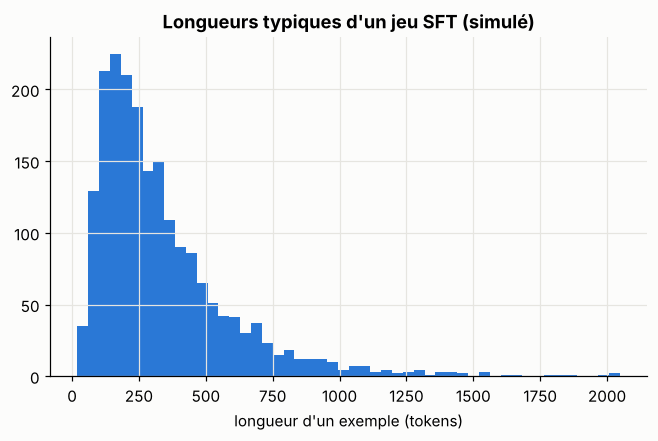

In [5]:
lengths = np.clip(rng.lognormal(mean=5.6, sigma=0.7, size=2000).astype(int), 20, 2048)
max_len, batch = 2048, 8

# padding: each batch padded to its longest sequence (random batches)
order = rng.permutation(len(lengths))
pad_tokens = sum(len(b) * max(lengths[b]) for b in np.array_split(order, len(order) // batch))
# packing: best-fit-decreasing into bins of max_len
bins = []
for L in sorted(lengths, reverse=True):
    for i, used in enumerate(bins):
        if used + L <= max_len:
            bins[i] += L; break
    else:
        bins.append(L)
pack_tokens = len(bins) * max_len
real = lengths.sum()
print(f"real tokens: {real:,}")
print(f"padding  : {pad_tokens:,} processed tokens -> efficiency {real / pad_tokens:.0%}")
print(f"packing  : {pack_tokens:,} processed tokens -> efficiency {real / pack_tokens:.0%} ({len(bins)} sequences of {max_len})")
plt.hist(lengths, bins=50, color=PALETTE[0]); plt.xlabel("longueur d'un exemple (tokens)"); plt.title("Longueurs typiques d'un jeu SFT (simulé)")
plt.show()

> ⚠️ **Le piège du packing** : sans précaution, l'attention d'un exemple « voit » l'exemple précédent dans la même séquence (contamination croisée), et les positions ne repartent pas de 0. Les implémentations récentes (TRL, `packing=True` avec des noyaux d'attention qui gèrent les frontières, par exemple via `position_ids` réinitialisés) isolent les exemples. Vérifie que ta configuration le fait, sinon préfère le regroupement par longueur (*bucketing*, module 1).

## 5. Le budget mémoire : affinage complet, LoRA, QLoRA

### 📐 Ce qui occupe la mémoire GPU

Pour $N$ paramètres, entraînés en précision mixte avec AdamW :

| Élément | Octets / paramètre (affinage complet) | LoRA | QLoRA |
|---|---|---|---|
| poids du modèle | 2 (bf16) | 2 (bf16, gelés) | ~0,5 (4 bits NF4) + constantes de quantification |
| gradients | 2 (bf16) ou 4 | seulement pour les adaptateurs | idem |
| états d'Adam ($m$, $v$) | 8 (2 × fp32) | seulement pour les adaptateurs | idem |
| copie maître fp32 des poids | 4 | — | — |
| **total (hors activations)** | **≈ 16** | **≈ 2 + petit** | **≈ 0,5–0,6 + petit** |

À cela s'ajoutent les **activations** (proportionnelles à la taille du batch, à la longueur des séquences et au nombre de couches), qu'on réduit par *gradient checkpointing* (recalculer au lieu de stocker, ~30 % de temps en plus).

1B   : LoRA r=16 trains   11.3 M parameters = 0.94% of the model
7–8B : LoRA r=16 trains   41.9 M parameters = 0.52% of the model
70B  : LoRA r=16 trains  209.7 M parameters = 0.30% of the model


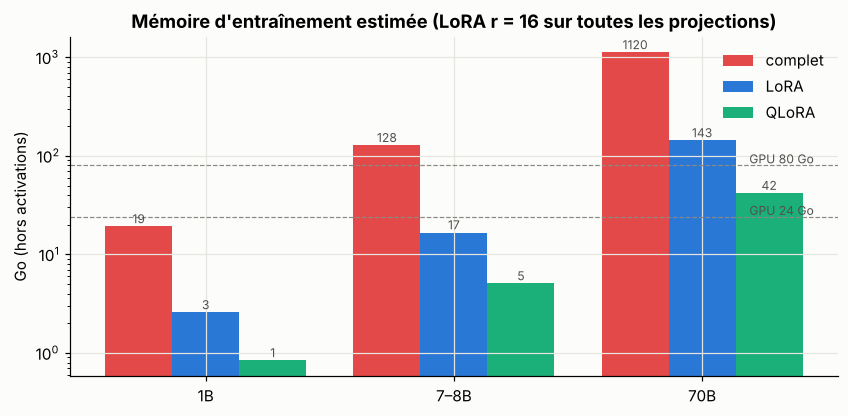

In [6]:
def trainable_lora_params(n_layers, d, d_ff, r, kv_dim=None, targets=("q", "k", "v", "o", "gate", "up", "down")):
    kv_dim = kv_dim or d
    shapes = {"q": (d, d), "k": (d, kv_dim), "v": (d, kv_dim), "o": (d, d), "gate": (d, d_ff), "up": (d, d_ff), "down": (d_ff, d)}
    return n_layers * sum(r * (a + b) for name, (a, b) in shapes.items() if name in targets)     # r(d_in + d_out) per matrix

def memory_gb(N, method, lora_params=0):
    if method == "complet":
        return 16 * N / 1e9
    if method == "LoRA":
        return (2 * N + 16 * lora_params) / 1e9
    if method == "QLoRA":
        return (0.55 * N + 16 * lora_params) / 1e9

configs = {"1B": (1.2e9, 16, 2048, 8192), "7–8B": (8.0e9, 32, 4096, 14336), "70B": (70e9, 80, 8192, 28672)}
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(configs))
for k, (method, c) in enumerate(zip(["complet", "LoRA", "QLoRA"], [PALETTE[7], PALETTE[0], PALETTE[2]])):
    vals = []
    for name, (N, L, d, dff) in configs.items():
        lp = trainable_lora_params(L, d, dff, r=16, kv_dim=d // 4)
        vals.append(memory_gb(N, method, lp))
    ax.bar(x + (k - 1) * 0.27, vals, 0.27, color=c, label=method)
    for xi, v in zip(x + (k - 1) * 0.27, vals):
        ax.text(xi, v * 1.08, f"{v:.0f}", ha="center", fontsize=8, color="#52514e")
for gpu, mem in [("GPU 24 Go", 24), ("GPU 80 Go", 80)]:
    ax.axhline(mem, color="#8a8984", ls="--", lw=0.8); ax.text(2.45, mem * 1.05, gpu, fontsize=8, color="#52514e", ha="right")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(configs.keys()); ax.set_ylabel("Go (hors activations)")
ax.set_title("Mémoire d'entraînement estimée (LoRA r = 16 sur toutes les projections)"); ax.legend()
plt.show()
for name, (N, L, d, dff) in configs.items():
    lp = trainable_lora_params(L, d, dff, r=16, kv_dim=d // 4)
    print(f"{name:5s}: LoRA r=16 trains {lp / 1e6:6.1f} M parameters = {lp / N:.2%} of the model")

(Configurations approximatives de modèles récents à attention groupée, où les projections $K$ et $V$ sont plus petites que $Q$. Les chiffres sont des **ordres de grandeur** : la mémoire réelle dépend des activations, du framework et des noyaux utilisés.)

**Lecture** : un modèle de 7–8 milliards de paramètres demande ~130 Go en affinage complet (plusieurs GPU), ~16 Go en LoRA et ~5 Go en QLoRA (plus les activations) : QLoRA le rend affinable sur un seul GPU grand public. Le coût est une légère perte de qualité due à la quantification et un entraînement un peu plus lent.

## 6. SFT avec TRL et LoRA / QLoRA

In [ ]:
# pip install -U trl peft transformers datasets accelerate bitsandbytes
import torch
from datasets import Dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from trl import SFTConfig, SFTTrainer

model_id = "Qwen/Qwen3-0.6B"            # start small to debug the pipeline, then scale up

# --- data: conversational format (one dict per example) ---
train_rows = [{"messages": [
    {"role": "system", "content": "Tu annotes des domaines V au format JSON."},
    {"role": "user", "content": "Séquence : EVQLVESGGGLVQPGGSLRLSCAAS..."},
    {"role": "assistant", "content": '{"FR1": [1, 25], "CDR1": [26, 33], "...": "..."}'},
]}] * 64                                 # placeholder: use your real, deduplicated examples
train_ds = Dataset.from_list(train_rows)

# --- QLoRA: 4-bit frozen base model + LoRA adapters in bf16 ---
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, dtype=torch.bfloat16, device_map="auto")
tokenizer = AutoTokenizer.from_pretrained(model_id)

peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])

args = SFTConfig(
    output_dir="sft-qlora",
    num_train_epochs=2,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,       # effective batch 16
    learning_rate=1e-4,                  # adapters: higher lr than full fine-tuning (~2e-5)
    lr_scheduler_type="cosine", warmup_ratio=0.05,
    max_length=2048,
    assistant_only_loss=True,            # section 3: loss on assistant turns only (needs a compatible chat template)
    packing=False,                       # section 4: enable only if your setup isolates packed examples
    gradient_checkpointing=True,
    bf16=True,
    logging_steps=10, save_strategy="epoch", report_to="none",
)
trainer = SFTTrainer(model=model, args=args, train_dataset=train_ds, processing_class=tokenizer, peft_config=peft_config)
trainer.train()
trainer.save_model("sft-qlora/final")    # saves only the LoRA adapter (a few dozen MB)

In [ ]:
# --- inference with the adapter, and merging for deployment ---
from peft import AutoPeftModelForCausalLM

ft = AutoPeftModelForCausalLM.from_pretrained("sft-qlora/final", dtype=torch.bfloat16, device_map="auto")
msgs = [{"role": "system", "content": "Tu annotes des domaines V au format JSON."},
        {"role": "user", "content": "Séquence : QVQLQESGPGLVKPSETLSLTCTVS..."}]
inputs = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(ft.device)
out = ft.generate(**inputs, max_new_tokens=200, do_sample=False)
print(tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

# merging a LoRA trained on a 4-bit base: reload the base in bf16 first, then merge (merging into 4-bit weights is lossy)
base = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16)
from peft import PeftModel
merged = PeftModel.from_pretrained(base, "sft-qlora/final").merge_and_unload()
merged.save_pretrained("sft-merged"); tokenizer.save_pretrained("sft-merged")

**Hyperparamètres de départ** (à ajuster sur la validation) :

| | Affinage complet | LoRA / QLoRA |
|---|---|---|
| learning rate | $1\cdot10^{-5}$ – $2\cdot10^{-5}$ | $1\cdot10^{-4}$ – $2\cdot10^{-4}$ |
| époques | 1–3 | 1–3 |
| rang $r$ / $\alpha$ | — | 8–64 / $\alpha = 2r$ |
| cibles | — | toutes les projections linéaires (attention + MLP) |

> 💡 **Sorties structurées** : si le modèle doit produire du JSON (annotations, appels d'outils), combine SFT et **décodage contraint** à l'inférence (grammaires JSON, par exemple avec `outlines`, `xgrammar` ou le mode « structured output » des serveurs d'inférence) : le fine-tuning apprend le contenu, la contrainte garantit la syntaxe.

## 7. Aligner sur des préférences : DPO

### 📐 De RLHF à DPO

On dispose de comparaisons : pour un prompt $x$, la réponse $y_w$ (*winner*) est préférée à $y_l$ (*loser*). Le **modèle de Bradley-Terry** relie une récompense latente $r(x,y)$ aux préférences :
$$
p(y_w\succ y_l\mid x) = \sigma\big(r(x, y_w) - r(x, y_l)\big)
$$

**RLHF** apprend d'abord $r$ sur les comparaisons, puis optimise la politique $\pi_\theta$ (le LLM) pour maximiser la récompense **sans trop s'éloigner** du modèle de référence $\pi_{\text{ref}}$ (le modèle SFT) :
$$
\max_{\pi}\ \mathbb E_{y\sim\pi(\cdot\mid x)}\big[r(x,y)\big] - \beta\,\mathrm{KL}\big(\pi(\cdot\mid x)\,\|\,\pi_{\text{ref}}(\cdot\mid x)\big)
$$

**L'observation clé de DPO** (Rafailov et al., 2023) : ce problème a une solution **analytique**,
$$
\pi^\star(y\mid x) = \frac{1}{Z(x)}\,\pi_{\text{ref}}(y\mid x)\exp\!\big(r(x,y)/\beta\big)
\quad\Longleftrightarrow\quad
r(x,y) = \beta\log\frac{\pi^\star(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \beta\log Z(x)
$$
La récompense est **implicitement** définie par la politique. En l'injectant dans Bradley-Terry, le terme $\log Z(x)$ (impossible à calculer) **s'annule** dans la différence $r(y_w) - r(y_l)$ :
$$
\boxed{\ \mathcal L_{\text{DPO}}(\theta) = -\,\mathbb E\left[\log\sigma\!\left(\beta\log\frac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)} - \beta\log\frac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\right)\right]\ }
$$
Plus de modèle de récompense, plus de RL : une simple **classification binaire** sur des paires, avec deux passes avant (politique et référence gelée). $\log\pi(y\mid x)$ est la somme des log-probabilités des tokens de la réponse.

### 📐 Le gradient

En notant $\hat r_\theta(y) = \beta\log\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)}$ la récompense implicite :
$$
\nabla_\theta\mathcal L_{\text{DPO}} = -\beta\,\mathbb E\Big[\underbrace{\sigma\big(\hat r_\theta(y_l) - \hat r_\theta(y_w)\big)}_{\text{poids : grand si le modèle se trompe}}\big(\nabla_\theta\log\pi_\theta(y_w\mid x) - \nabla_\theta\log\pi_\theta(y_l\mid x)\big)\Big]
$$
On augmente la vraisemblance de la bonne réponse, on diminue celle de la mauvaise, d'autant plus que le modèle les classe mal. $\beta$ règle la force de l'ancrage à la référence : petit $\beta$ = la politique peut s'éloigner beaucoup.

### 📊 Démonstration NumPy

Un « LLM » miniature : pour chacun de 30 prompts, la politique choisit parmi 6 réponses candidates, $\pi_\theta(y\mid x) = \mathrm{softmax}(\theta_x)_y$. Une **récompense cachée** (la vraie préférence humaine) génère des paires de préférences bruitées. On entraîne par DPO, et on regarde : la politique apprend-elle à préférer les bonnes réponses ? La récompense implicite retrouve-t-elle le classement ? Combien la politique s'éloigne-t-elle de la référence selon $\beta$ ?

In [7]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True); e = np.exp(z); return e / e.sum(axis=axis, keepdims=True)

n_prompts, n_resp = 30, 6
true_reward = rng.normal(0, 1.5, (n_prompts, n_resp))                   # hidden human preferences
ref_logits = rng.normal(0, 1.0, (n_prompts, n_resp))                     # the SFT model, before alignment


def make_pairs(n_pairs, seed=0):
    r = np.random.default_rng(seed)
    x = r.integers(0, n_prompts, n_pairs)
    y1, y2 = r.integers(0, n_resp, n_pairs), r.integers(0, n_resp, n_pairs)
    keep = y1 != y2
    x, y1, y2 = x[keep], y1[keep], y2[keep]
    p_y1_wins = 1 / (1 + np.exp(-(true_reward[x, y1] - true_reward[x, y2])))   # Bradley-Terry labels (noisy)
    y1_wins = r.random(len(x)) < p_y1_wins
    return x, np.where(y1_wins, y1, y2), np.where(y1_wins, y2, y1)


def train_dpo(beta, pairs, steps=3000, lr=0.5):
    x, yw, yl = pairs
    theta = ref_logits.copy()
    logp_ref = np.log(softmax(ref_logits))
    for _ in range(steps):
        logp = np.log(softmax(theta))
        margin = beta * ((logp[x, yw] - logp_ref[x, yw]) - (logp[x, yl] - logp_ref[x, yl]))
        w = 1 / (1 + np.exp(margin))                                    # sigma(-margin): weight of each pair
        # d log p_y / d theta_x = onehot(y) - p : the "- p" terms of y_w and y_l cancel in the difference
        grad = np.zeros_like(theta)
        np.add.at(grad, (x, yw), -beta * w)
        np.add.at(grad, (x, yl), beta * w)
        theta -= (lr / beta) * grad / len(x)        # step scaled by 1/beta so every beta is trained to convergence
    return theta


pairs = make_pairs(3000)
print(f"{len(pairs[0])} preference pairs")

def evaluate_policy(theta, beta):
    P, Pref = softmax(theta), softmax(ref_logits)
    exp_reward = (P * true_reward).sum(1).mean()
    kl = (P * (np.log(P) - np.log(Pref))).sum(1).mean()
    implicit = beta * (np.log(P) - np.log(Pref))                          # implicit reward (up to a per-prompt constant)
    corr = np.mean([np.corrcoef(implicit[i], true_reward[i])[0, 1] for i in range(n_prompts)])
    return exp_reward, kl, corr

print(f"reference policy: expected true reward {(softmax(ref_logits) * true_reward).sum(1).mean():.3f} "
      f"| best possible {true_reward.max(1).mean():.3f}")
rows = []
for beta in [0.05, 0.1, 0.3, 1.0, 3.0]:
    th = train_dpo(beta, pairs)
    er, kl, corr = evaluate_policy(th, beta)
    rows.append((beta, er, kl, corr))
    print(f"beta={beta:<5} expected true reward {er:.3f} | KL(pi || pi_ref) {kl:.3f} | corr(implicit reward, true reward) {corr:.3f}")
rows = np.array(rows)

2526 preference pairs
reference policy: expected true reward 0.051 | best possible 1.982
beta=0.05  expected true reward 1.767 | KL(pi || pi_ref) 1.445 | corr(implicit reward, true reward) 0.934
beta=0.1   expected true reward 1.735 | KL(pi || pi_ref) 1.350 | corr(implicit reward, true reward) 0.937
beta=0.3   expected true reward 1.584 | KL(pi || pi_ref) 1.011 | corr(implicit reward, true reward) 0.943
beta=1.0   expected true reward 1.126 | KL(pi || pi_ref) 0.431 | corr(implicit reward, true reward) 0.947
beta=3.0   expected true reward 0.582 | KL(pi || pi_ref) 0.101 | corr(implicit reward, true reward) 0.947


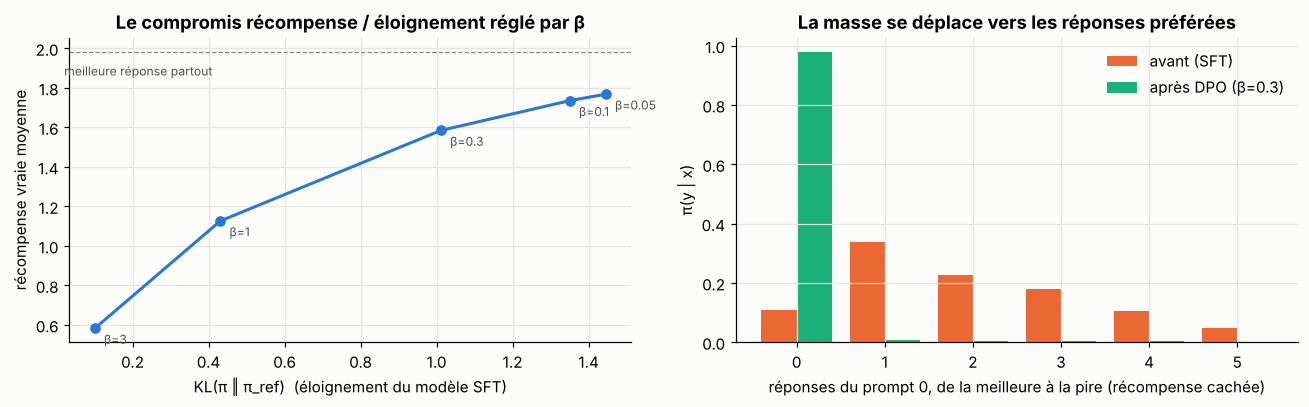

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(rows[:, 2], rows[:, 1], "o-", color=PALETTE[0])
for b, kl, er in zip(rows[:, 0], rows[:, 2], rows[:, 1]):
    axes[0].annotate(f"β={b:g}", (kl, er), xytext=(6, -10), textcoords="offset points", fontsize=8, color="#52514e")
axes[0].axhline(true_reward.max(1).mean(), color="#8a8984", ls="--", lw=0.8); axes[0].text(0.02, true_reward.max(1).mean() - 0.12, "meilleure réponse partout", fontsize=8, color="#52514e")
axes[0].set_xlabel("KL(π ‖ π_ref)  (éloignement du modèle SFT)"); axes[0].set_ylabel("récompense vraie moyenne")
axes[0].set_title("Le compromis récompense / éloignement réglé par β")
th = train_dpo(0.3, pairs); P0, P1 = softmax(ref_logits)[0], softmax(th)[0]
order = np.argsort(-true_reward[0])
axes[1].bar(np.arange(n_resp) - 0.2, P0[order], 0.4, color=PALETTE[1], label="avant (SFT)")
axes[1].bar(np.arange(n_resp) + 0.2, P1[order], 0.4, color=PALETTE[2], label="après DPO (β=0.3)")
axes[1].set_xlabel("réponses du prompt 0, de la meilleure à la pire (récompense cachée)"); axes[1].set_ylabel("π(y | x)")
axes[1].set_title("La masse se déplace vers les réponses préférées"); axes[1].legend()
plt.tight_layout(); plt.show()

**Lecture critique** :
- DPO déplace la politique vers les réponses préférées et sa **récompense implicite** retrouve le classement caché, sans jamais avoir appris de modèle de récompense explicite.
- $\beta$ règle le compromis : petit $\beta$ = gros gain de récompense mais forte **dérive** par rapport au modèle SFT (sur un vrai LLM, cette dérive se traduit par des réponses dégénérées, trop longues, ou un oubli de compétences) ; grand $\beta$ = politique prudente. Valeurs usuelles : 0,05 à 0,5.
- Le gain est plafonné par la **qualité des préférences** : des préférences bruitées ou biaisées (par exemple, des annotateurs qui préfèrent systématiquement les réponses longues) sont apprises fidèlement. DPO optimise ce que les données préfèrent, pas ce qui est vrai.

## 8. DPO avec TRL ; au-delà

In [ ]:
from datasets import Dataset
from trl import DPOConfig, DPOTrainer

pref_rows = [
    {"prompt": [{"role": "user", "content": "Résume la fonction des CDR en une phrase."}],
     "chosen": [{"role": "assistant", "content": "Les CDR forment l'essentiel du site de liaison à l'antigène."}],
     "rejected": [{"role": "assistant", "content": "Les CDR sont des régions très importantes qui ont de nombreuses fonctions variées dans de multiples contextes biologiques..."}]},
] * 32                                                    # placeholder: real preference pairs
pref_ds = Dataset.from_list(pref_rows)

policy = AutoModelForCausalLM.from_pretrained("sft-merged", dtype=torch.bfloat16, device_map="auto")   # start from the SFT model
dpo_args = DPOConfig(output_dir="dpo", beta=0.1, learning_rate=5e-7, num_train_epochs=1,
                     per_device_train_batch_size=2, gradient_accumulation_steps=8, bf16=True, report_to="none")
dpo_trainer = DPOTrainer(model=policy, args=dpo_args, train_dataset=pref_ds, processing_class=tokenizer,
                         peft_config=LoraConfig(r=16, lora_alpha=32, task_type="CAUSAL_LM"))   # with LoRA, the frozen base acts as the reference
dpo_trainer.train()
# Watch the logged metrics: rewards/chosen, rewards/rejected, rewards/margins, rewards/accuracies

> ⚠️ DPO utilise un learning rate **beaucoup plus petit** que le SFT (de l'ordre de $10^{-7}$ à $10^{-6}$ en affinage complet). Surveille la log-vraisemblance des réponses *choisies* : si elle **baisse** aussi (les deux baissent, la marge augmente), le modèle « triche » en dégradant tout, un phénomène connu de DPO.

### Au-delà : l'apprentissage par renforcement à récompenses vérifiables

Quand la qualité d'une réponse est **vérifiable automatiquement** (un calcul juste, un code qui passe des tests, un JSON qui valide un schéma, une annotation identique à une référence), on peut se passer de préférences humaines : on génère plusieurs réponses par prompt, on les note, et on renforce les meilleures. **GRPO** (Shao et al., 2024, popularisé par DeepSeek-R1) utilise comme avantage la récompense **normalisée au sein du groupe** de $G$ réponses d'un même prompt :
$$
A_i = \frac{r_i - \mathrm{moyenne}(r_1,\dots,r_G)}{\mathrm{écart\text{-}type}(r_1,\dots,r_G)}
$$
ce qui évite d'entraîner un réseau critique. TRL fournit `GRPOTrainer`, auquel on passe une ou plusieurs **fonctions de récompense** Python. Pour une tâche d'annotation structurée, une récompense naturelle combine validité du format et accord avec la référence (par exemple un F1 de frontières, module 10).

## 9. Évaluer un LLM affiné

| Question | Mesure |
|---|---|
| La tâche est-elle mieux faite ? | métrique de la tâche sur un **test jamais vu** (exactitude, F1, validité JSON…) ; comparer au modèle de base **bien prompté** (few-shot) |
| Le modèle a-t-il oublié ? | quelques benchmarks généraux avant / après (oubli catastrophique, module 8) |
| Le format est-il respecté ? | taux de sorties valides (parsing, schéma) |
| Les préférences sont-elles mieux suivies ? | taux de victoire contre la référence, jugé par des humains ou un LLM juge |
| Contamination ? | vérifier que le test n'est pas dans les données d'entraînement (dédupliquer, module 8) |

> ⚠️ **LLM comme juge** : pratique mais biaisé (préférence pour les réponses longues, pour la première position, pour son propre style). Contre-mesures : comparer les deux ordres, fixer une grille de critères, valider le juge sur un échantillon annoté par des humains, et ne jamais l'utiliser seul pour une conclusion publiée.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Quand fine-tuner | comportement, format, compétence ; les **connaissances** vont plutôt au RAG |
| Chat template | indispensable et propre à chaque modèle ; `apply_chat_template` |
| Perte | uniquement sur les réponses de l'assistant **et** leur token de fin |
| Packing | gros gain d'efficacité ; isoler les exemples |
| Mémoire | ≈ 16 o/param en complet, ≈ 2 en LoRA, ≈ 0,5 en QLoRA (+ activations) |
| SFT TRL | `SFTTrainer` + `SFTConfig(assistant_only_loss=True)` + `LoraConfig` |
| DPO | $-\log\sigma\big(\beta[\log\frac{\pi}{\pi_{\text{ref}}}(y_w) - \log\frac{\pi}{\pi_{\text{ref}}}(y_l)]\big)$ ; $\beta$ = ancrage |
| RL vérifiable | GRPO : avantage normalisé dans le groupe ; récompenses programmées |
| Évaluation | test jamais vu, baseline prompté, oubli, validité, juge LLM avec précautions |

### 🏋️ Exercices

1. **Masque.** Modifie `build_example` pour ne garder la perte que sur le **dernier** tour de l'assistant. Dans quels cas est-ce préférable ?
2. **β.** Dans la démonstration DPO, réduis le nombre de paires à 200. Comment évolue le compromis récompense / KL ? Pourquoi un grand $\beta$ protège-t-il du sur-apprentissage des préférences ?
3. **Biais de longueur.** Ajoute à la récompense cachée un terme qui favorise les « réponses longues » (un attribut de chaque réponse). Montre que DPO l'apprend, puis propose une correction (normaliser par la longueur, ou équilibrer les paires).
4. **Mémoire.** Ajoute à `memory_gb` une estimation des activations : $\approx 2\cdot B\cdot T\cdot d\cdot L\cdot c$ octets (avec $c\approx 10$–$30$ selon l'implémentation). À partir de quelle longueur de séquence les activations dominent-elles pour un modèle 7–8B en QLoRA ?
5. **Ton projet.** Rédige 20 exemples conversationnels pour une tâche d'annotation de ton domaine, au format TRL, avec une sortie JSON. Écris la fonction de récompense que tu utiliserais pour GRPO.

<details><summary>Indications</summary>

1. Utile quand les tours précédents de l'assistant viennent d'un autre modèle (données synthétiques de qualité variable) : on ne veut pas les imiter.
2. Avec peu de paires, la politique sur-ajuste les préférences bruitées ; l'ancrage KL limite les dérives.
3. DPO n'a aucun moyen de distinguer « préféré parce que meilleur » de « préféré parce que plus long ».
</details>

**➡️ Module suivant : tool calling, agents et MCP** (faire agir un LLM : schémas d'outils, boucle d'agent, protocole MCP, recherche en ligne, sécurité).